In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [ ]:
!kaggle datasets download -d salader/dogs-vs-cats

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata


In [ ]:
!kaggle config view

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:
!kaggle datasets list -s dogs

You must authenticate before you can call the Kaggle API.
Follow the instructions to authenticate at: https://github.com/Kaggle/kaggle-cli/blob/main/docs/README.md#authentication


In [ ]:
!pip install -q --upgrade kaggle


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 256.8/256.8 kB 17.0 MB/s eta 0:00:00


In [ ]:
!kaggle datasets download -d salader/dogsvscats --unzip

Dataset URL: https://www.kaggle.com/datasets/salader/dogsvscats
License(s): unknown
100% 1.06G/1.06G [00:11<00:00, 101MB/s]



In [ ]:
!kaggle datasets download -d salader/dogs-vs-cats

403 Client Error: Forbidden for url: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDatasetMetadata


In [ ]:
import zipfile

zip_ref = zipfile.ZipFile('/content/dogsvscats.zip', 'r')
zip_ref.extractall('/content')
zip_ref.close()

FileNotFoundError: [Errno 2] No such file or directory: '/content/dogsvscats.zip'

In [ ]:
!ls /content

catsvsdogs  sample_data  test  train


In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense,Conv2D,MaxPooling2D,Flatten,BatchNormalization,Dropout

In [ ]:
# generators divide the data into batches so that if doesnt affect ram its used to process large amt of data
train_ds =tf.keras.utils.image_dataset_from_directory(
    directory='/content/train',
    labels='inferred',
    label_mode='int',# cats 0 , dogs 1
    batch_size=32,
    image_size=(256,256)  # reshape in 256,256,3 coz images have diff size this will reshape all in same size
)
validation_ds=tf.keras.utils.image_dataset_from_directory(
    directory='/content/test',
    labels='inferred',
    label_mode='int',# cats 0 , dogs 1
    batch_size=32,
    image_size=(256,256)  # reshape in 256,256,3 coz images have diff size this will reshape all in same size
)

Found 20000 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.


In [ ]:
# normalize the dataset from 0,255 to 0,1
def process(image,label):
  image = tf.cast(image/255. ,tf.float32)
  return image,label

train_ds = train_ds.map(process)
validation_ds = validation_ds.map(process)
#  map function will send data one by one to process fun and there it will be transformed and then stored it in its place

In [ ]:
## now we will build cnn model

model = Sequential()
model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides = 2,padding='valid'))

#64 filters
model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides = 2,padding='valid'))

#128 filters
model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2,2),strides = 2,padding='valid'))

model.add(Flatten())


#fully connected layer
model.add(Dense(128,activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.1))
model.add(Dense(1,activation='sigmoid'))

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 254, 254, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 125, 125, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 60, 60, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,848,193 (56.64 MB)

 Trainable params: 14,847,745 (56.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
history = model.fit(train_ds,epochs=10,validation_data=validation_ds)

Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 70s 100ms/step - accuracy: 0.5850 - loss: 1.2045 - val_accuracy: 0.6052 - val_loss: 0.6587
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.6991 - loss: 0.5724 - val_accuracy: 0.7048 - val_loss: 0.5776
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.7591 - loss: 0.4913 - val_accuracy: 0.7292 - val_loss: 0.5362
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 89ms/step - accuracy: 0.8003 - loss: 0.4300 - val_accuracy: 0.7694 - val_loss: 0.4831
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 81s 88ms/step - accuracy: 0.8328 - loss: 0.3677 - val_accuracy: 0.8156 - val_loss: 0.4288
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 88ms/step - accuracy: 0.8626 - loss: 0.3058 - val_accuracy: 0.7970 - val_loss: 0.4808
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 58s 93ms/step - accuracy: 0.8917 - loss: 0.2463 - val_accuracy: 0.8174 - val_loss: 0.4583
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 86ms/step - accuracy: 0.9132 - loss: 0.1985 -

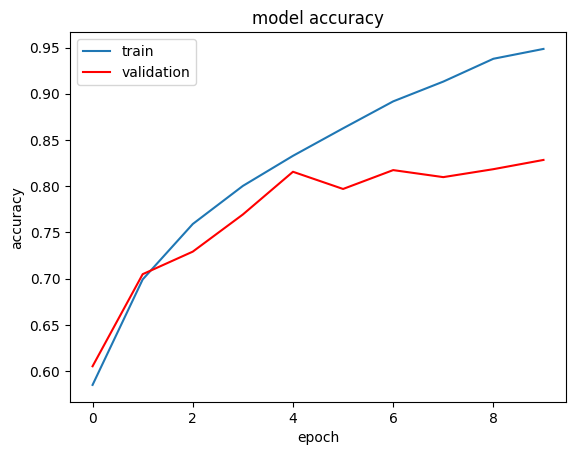

In [ ]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'],c='red')
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train','validation'],loc='upper left')

In [ ]:
# there is a gap which tells overfitting

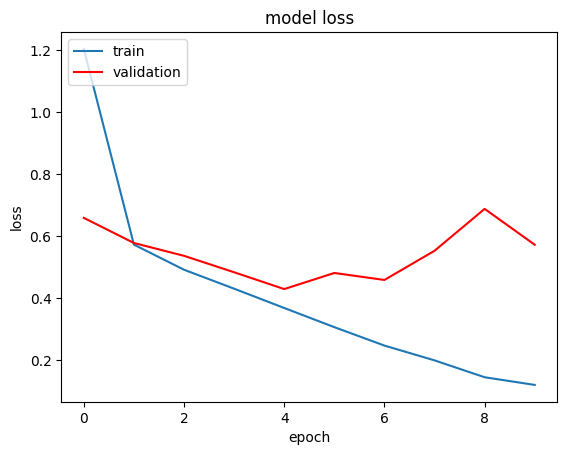

In [ ]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'],c='red')
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train','validation'],loc='upper left')

In [ ]:
# again gap ---> overfitting

In [ ]:
# ways to reduce overfitting
# more data
# data augumentation
#L1/L2 Regularizer
# dropout
#batch norm
#reduce complexity

In [ ]:
import cv2

In [ ]:
test_img = cv2.imread('/content/OIP.webp')

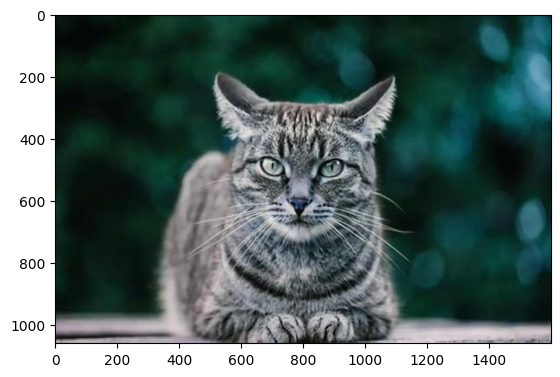

In [ ]:
plt.imshow(test_img)

In [ ]:
test_img.shape

(1060, 1600, 3)

In [ ]:
test_img = cv2.resize(test_img,(256,256))

In [ ]:
test_input = test_img.reshape((1,256,256,3))
# since we pass data in batches so we gave it as 4D tensor which means it has 1 img of dimn 256 256 3


In [ ]:
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


array([[0.]], dtype=float32)

In [ ]:
test_img1 = cv2.resize(test_img1,(256,256))
test_input1 = test_img1.reshape((1,256,256,3))
model.predict(test_input)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


array([[0.]], dtype=float32)

In [ ]:
test_img = cv2.imread('/content/Pomeranian-1.webp')
test_img = cv2.resize(test_img, (256, 256))
test_img = test_img / 255.0
test_input = test_img.reshape(1, 256, 256, 3)

# prediction = model.predict(test_input)
# print(prediction)
# model.predict(test_input)
prediction = model.predict(test_input)

if prediction[0][0] > 0.5:
    print("Dog 🐶")
else:
    print("Cat 🐱")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step
Cat 🐱


In [ ]:
print(test_img)
print(test_img.shape if test_img is not None else "Image not loaded")

[[[0.05882353 0.0745098  0.0627451 ]
  [0.04313725 0.08235294 0.06666667]
  [0.03921569 0.09019608 0.06666667]
  ...
  [0.01960784 0.24313725 0.25098039]
  [0.         0.19607843 0.20784314]
  [0.         0.16862745 0.18431373]]

 [[0.05098039 0.0745098  0.0627451 ]
  [0.04313725 0.08627451 0.05882353]
  [0.03921569 0.09411765 0.05882353]
  ...
  [0.01960784 0.23921569 0.26666667]
  [0.         0.19607843 0.21568627]
  [0.         0.17254902 0.18823529]]

 [[0.02745098 0.07843137 0.0627451 ]
  [0.03529412 0.09411765 0.04705882]
  [0.04705882 0.09411765 0.05882353]
  ...
  [0.03137255 0.26666667 0.29411765]
  [0.00784314 0.23137255 0.24705882]
  [0.00392157 0.18823529 0.21176471]]

 ...

 [[0.42745098 0.41176471 0.42352941]
  [0.43529412 0.41568627 0.41960784]
  [0.44313725 0.41568627 0.41960784]
  ...
  [0.50588235 0.50980392 0.52941176]
  [0.50980392 0.51372549 0.52941176]
  [0.63137255 0.63529412 0.65490196]]

 [[0.62745098 0.6        0.62352941]
  [0.64705882 0.61176471 0.63529412]


In [ ]:
import cv2
import numpy as np

img = cv2.imread('/content/OIP.webp')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (256, 256))
img = img.astype('float32') / 255.0

test_input = np.expand_dims(img, axis=0)

pred = model.predict(test_input)[0][0]

print("Probability:", pred)

if pred > 0.5:
    print("Dog 🐶")
else:
    print("Cat 🐱")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step
Probability: 1.045098e-05
Cat 🐱
